<a href="https://colab.research.google.com/github/mahapatramadhu-ops/python-/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing  import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [5]:
data = pd.read_csv("/content/malnutrition_data (1).csv")
print (data.head())

   age_months  weight_kg   height_cm    muac_cm   bmi nutrition_status
0   12.345052   3.000000   54.134002  13.160919  10.0           normal
1   30.807200   5.459076   76.199180  13.944380  10.0           normal
2   15.723226   3.000000   60.280820  13.243565  10.0           normal
3   57.796256  10.103074  104.990471  14.105683  10.0           normal
4   40.321320   7.110583   85.277902  14.641630  10.0           normal


In [17]:
X = data [["height_cm","weight_kg"]]
y = data [["nutrition_status"]]

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 2)
Testing data: (1000, 2)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [20]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)


knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
['normal' 'normal' 'moderate' 'moderate' 'normal' 'normal' 'moderate'
 'normal' 'normal' 'normal']


/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [21]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("KNN Accuracy:", accuracy)
print("KNN Accuracy (%):", accuracy * 100)

KNN Accuracy: 0.768
KNN Accuracy (%): 76.8


In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

    moderate       0.55      0.58      0.56       220
      normal       0.86      0.89      0.87       710
      severe       0.32      0.13      0.18        70

    accuracy                           0.77      1000
   macro avg       0.57      0.53      0.54      1000
weighted avg       0.75      0.77      0.76      1000



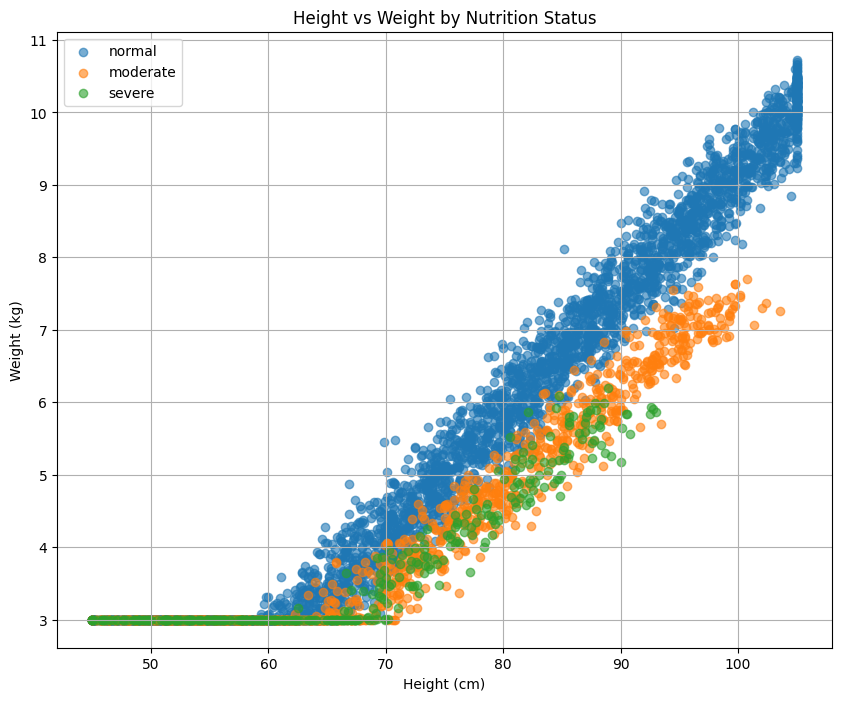

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

# Assuming 'data' is your DataFrame and 'nutrition_status' is the column for categories
for status in data['nutrition_status'].unique():
    subset = data[data['nutrition_status'] == status]
    plt.scatter(
        subset['height_cm'],
        subset['weight_kg'],
        label=status,
        alpha=0.6
    )

plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('Height vs Weight by Nutrition Status')
plt.legend()
plt.grid(True)
plt.show()

Enter the height in cm: 114
Enter the weight in kg: 25


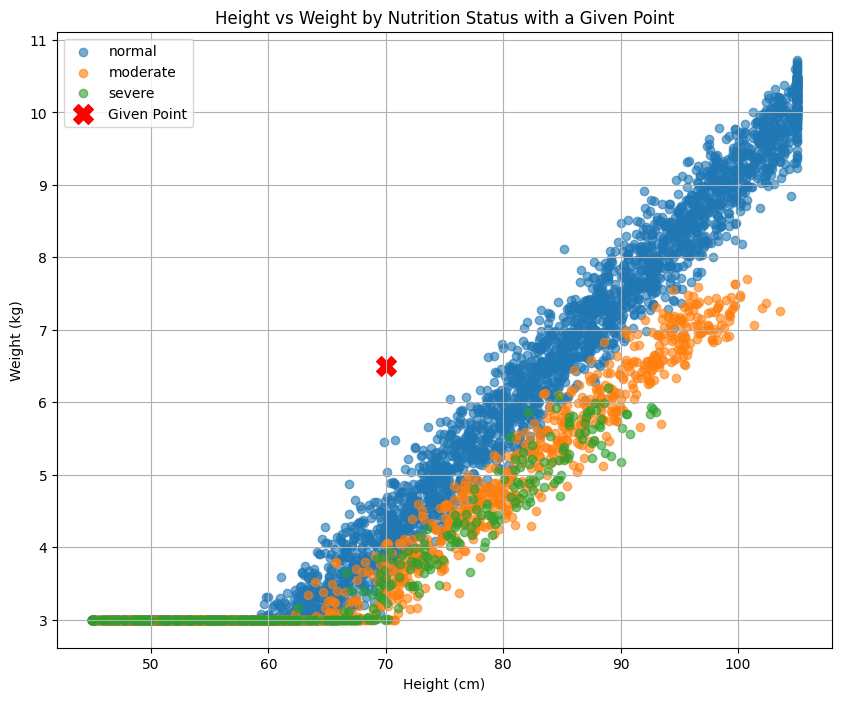

In [31]:
import matplotlib.pyplot as plt

height = float((input("Enter the height in cm: ")))
weight = float((input("Enter the weight in kg: ")))

plt.figure(figsize=(10, 8))

# Recreate the 'Height vs Weight by Nutrition Status' plot
for status in data['nutrition_status'].unique():
    subset = data[data['nutrition_status'] == status]
    plt.scatter(
        subset['height_cm'],
        subset['weight_kg'],
        label=status,
        alpha=0.6
    )

# Plot the new given point
plt.scatter(
    new_height,
    new_weight,
    color='red',
    marker='X',
    s=200, # Large marker size to make it stand out
    label='Given Point'
)

plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('Height vs Weight by Nutrition Status with a Given Point')
plt.legend()
plt.grid(True)
plt.show()